Epoch 1: Error = 2
Epoch 2: Error = 2
Epoch 3: Error = 1
Epoch 4: Error = 0
Epoch 5: Error = 0
Epoch 6: Error = 0
Epoch 7: Error = 0
Epoch 8: Error = 0
Epoch 9: Error = 0
Epoch 10: Error = 0

Final Weights: [-0.1  0.1  0.1]

Predictions:
[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 1


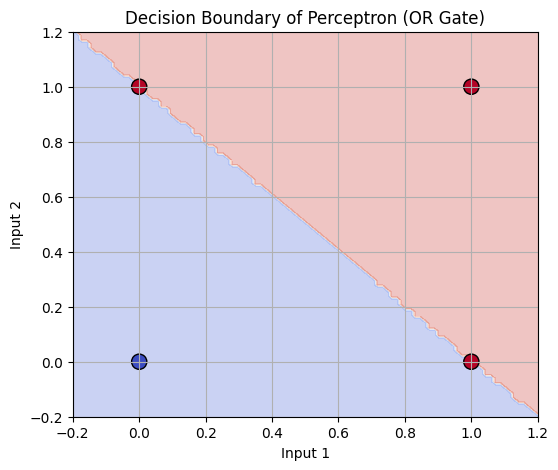

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def step_function(x):
    return np.where(x >= 0, 1, 0)

class Perceptron:
    def __init__(self, input_size, learning_rate=0.1, epochs=10):
        self.weights = np.zeros(input_size + 1) 
        self.lr = learning_rate
        self.epochs = epochs

    def predict(self, x):
        x = np.insert(x, 0, 1)  
        return step_function(np.dot(self.weights, x))

    def train(self, X, y):
        for epoch in range(self.epochs):
            total_error = 0

            for xi, target in zip(X, y):
                xi_bias = np.insert(xi, 0, 1)

                output = step_function(np.dot(self.weights, xi_bias))
                error = target - output
                total_error += abs(error)

                self.weights += self.lr * error * xi_bias

            print(f"Epoch {epoch+1}: Error = {total_error}")

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 1])

# NOR gate 
# y = np.array([1, 0, 0, 0])

p = Perceptron(input_size=2)
p.train(X, y)

print("\nFinal Weights:", p.weights)

print("\nPredictions:")
for sample in X:
    print(sample, "->", p.predict(sample))

def plot_decision_boundary(model, X, y):
    x_min, x_max = -0.2, 1.2
    y_min, y_max = -0.2, 1.2

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 100),
        np.linspace(y_min, y_max, 100)
    )

    Z = np.array([
        model.predict(np.array([x, y]))
        for x, y in zip(xx.ravel(), yy.ravel())
    ])

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(6,5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.coolwarm,
                edgecolors='black', s=120)

    plt.title("Decision Boundary of Perceptron (OR Gate)")
    plt.xlabel("Input 1")
    plt.ylabel("Input 2")
    plt.grid(True)
    plt.show()

plot_decision_boundary(p, X, y)